# Week 4A ? DESI normalization and photutils pseudo-labels

This notebook streams 3,000 Legacy Survey cutouts, estimates a per-band background and RMS, builds the Week 1 g/r/z asinh RGB representation, creates three-class source masks, saves a persistent 70/10/20 split, and presents a 50-image visual quality check. The arrays are disk-backed to limit Colab RAM use. Run from the `Week-4/` folder after cloning the repository.

**Important review step:** inspect the 50-image gallery. Put clearly broken cutout IDs in `MANUAL_DROP_IDS` in the review cell before running it. The notebook always excludes empty/no-target labels automatically. Candidate hard examples are generated from the held-out test split for visual selection.


In [1]:
# Colab/Kaggle dependencies; PyTorch is preinstalled in these runtimes.
%pip -q install datasets photutils astropy scipy pillow matplotlib pandas


In [2]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/Week-4

Mounted at /content/drive
/content/drive/MyDrive/Week-4


In [3]:
from pathlib import Path
import sys, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / 'src' / 'week4_data.py').exists():
    raise FileNotFoundError('Run this notebook with the working directory set to the Week-4 folder from the repository.')
sys.path.insert(0, str(ROOT / 'src'))
import importlib, week4_data
importlib.reload(week4_data)  # load current pipeline code after updating the Week-4 folder
from week4_data import create_dataset, update_valid_indices

SEED = 42
N_IMAGES = 3000
SHUFFLE_BUFFER = 64  # limits the HF stream buffer to reduce peak RAM
random.seed(SEED); np.random.seed(SEED)
DATA_DIR = ROOT / 'data'
PSEUDO_DIR = ROOT / 'results' / 'pseudo_labels'
PSEUDO_DIR.mkdir(parents=True, exist_ok=True)
print('Project:', ROOT, '| cutouts:', N_IMAGES)


Project: /content/drive/MyDrive/Week-4 | cutouts: 3000


## 1. Stream, normalize, label, and save the persistent split

The loader reads raw g/r/z fluxes and inverse-variance coverage; it does not assume that True in the survey mask means invalid. `Background2D` estimates each band?s local sky and RMS; normalized residual bands are combined with the Week 1 Legacy Survey asinh RGB mapping. Pseudo-label detection uses the summed g+r+z image, background subtraction, Gaussian smoothing, a 1.5-sigma threshold, a 10-pixel minimum area, and deblending.

Outputs: `data/rgb_images.npy`, `data/image_ids.npy`, `data/splits.json`, `data/normalization_and_qc.csv`, `results/pseudo_labels/masks.npy`, and a completion marker. Restarting with the same count reuses a complete cache. Keep `splits.json` unchanged through Week 8.


In [4]:
prepared = create_dataset(ROOT, n_images=N_IMAGES, seed=SEED, resume=True, buffer_size=SHUFFLE_BUFFER)
print('Finished:', prepared['n_images'], 'images; reused existing cache:', prepared.get('resumed', False))


README.md:   0%|          | 0.00/19.2k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/165 [00:00<?, ?it/s]

Prepared 50/3000 cutouts


Prepared 100/3000 cutouts


Prepared 150/3000 cutouts


Prepared 200/3000 cutouts


... (54 outputs left out)

Prepared 2850/3000 cutouts


Prepared 2900/3000 cutouts


Prepared 2950/3000 cutouts


Prepared 3000/3000 cutouts
Finished: 3000 images; reused existing cache: False


In [5]:
split = json.loads((DATA_DIR / 'splits.json').read_text(encoding='utf-8'))
ids = np.load(DATA_DIR / 'image_ids.npy', mmap_mode='r').astype(str)
masks = np.load(PSEUDO_DIR / 'masks.npy', mmap_mode='r')
rgb = np.load(DATA_DIR / 'rgb_images.npy', mmap_mode='r')
print({k: len(split[f'{k}_indices']) for k in ('train','validation','test')})
print('RGB:', rgb.shape, rgb.dtype, '| labels:', masks.shape, masks.dtype)
qc = pd.read_csv(DATA_DIR / 'normalization_and_qc.csv')
display(qc['status'].value_counts(dropna=False).rename_axis('label status').to_frame('images'))
display(pd.DataFrame({'class_id':[0,1,2], 'class':['background','target galaxy','other sources'],
                      'pixels':[sum(int(np.count_nonzero(masks[s:s+100] == c)) for s in range(0,len(masks),100)) for c in range(3)]}))


{'train': 2100, 'validation': 300, 'test': 600}
RGB: (3000, 160, 160, 3) uint8 | labels: (3000, 160, 160) uint8


,images
label status,
ok,3000


,class_id,class,pixels
0,0,background,66843537
1,1,target galaxy,1498163
2,2,other sources,8458300


## 2. Review about 50 pseudo-labels

Each row shows RGB and the three-class source map. The color IDs are 0 background, 1 target, and 2 other detected sources. Review every page and note failures such as fragments, missed faint outskirts, merged neighbours, or a non-galaxy chosen as the central target.


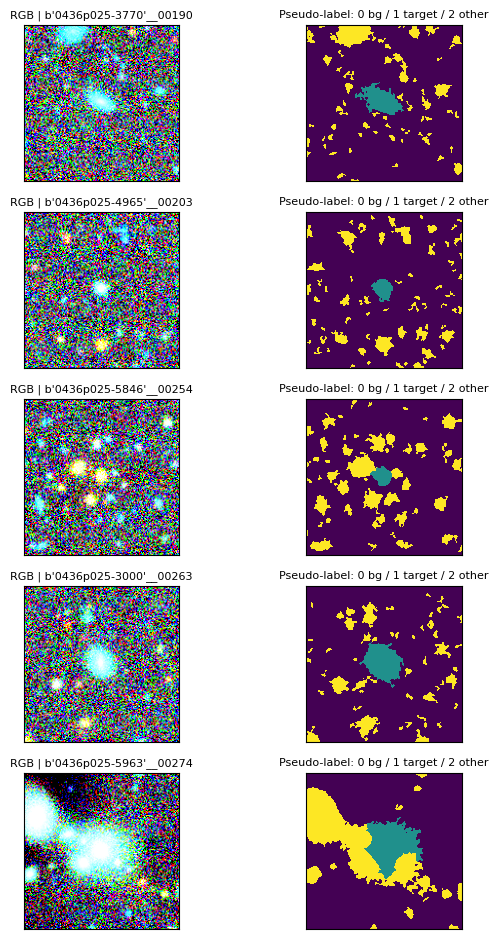

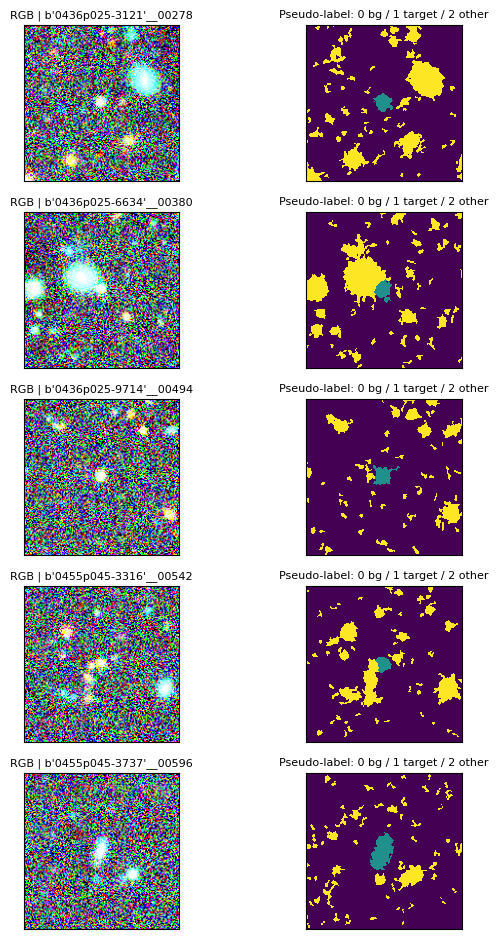

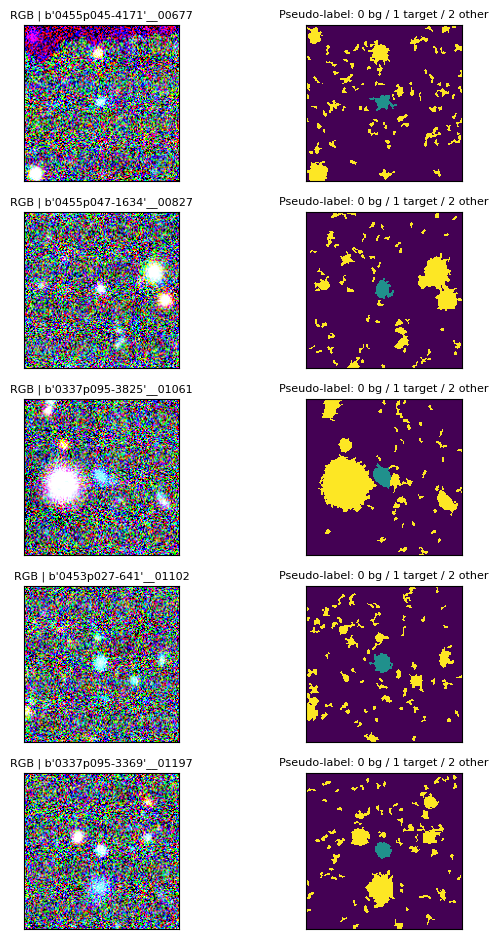

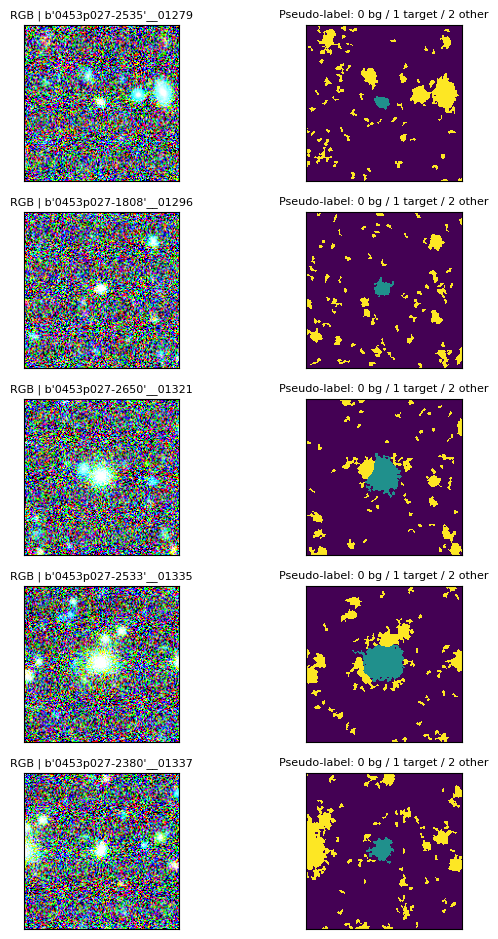

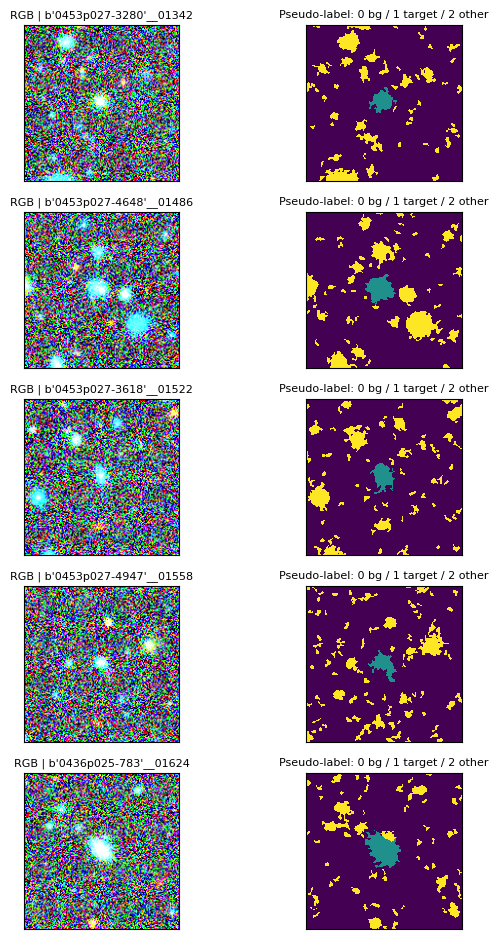

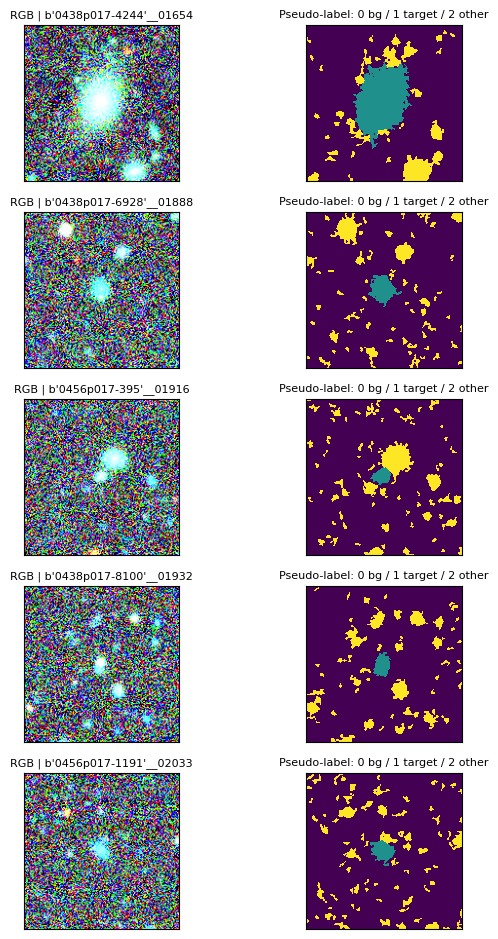

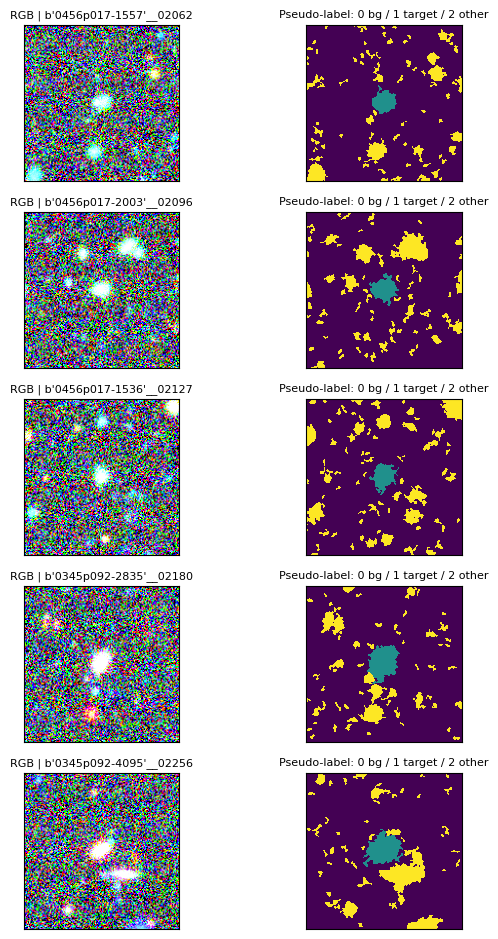

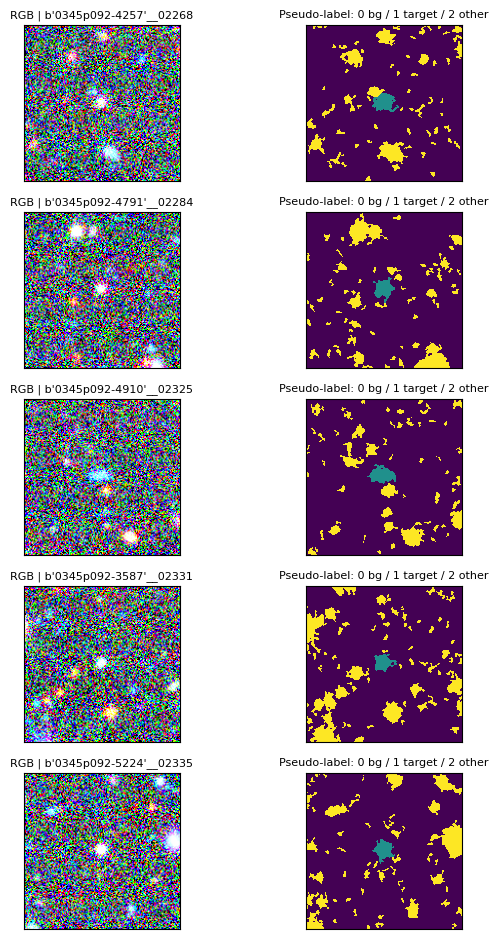

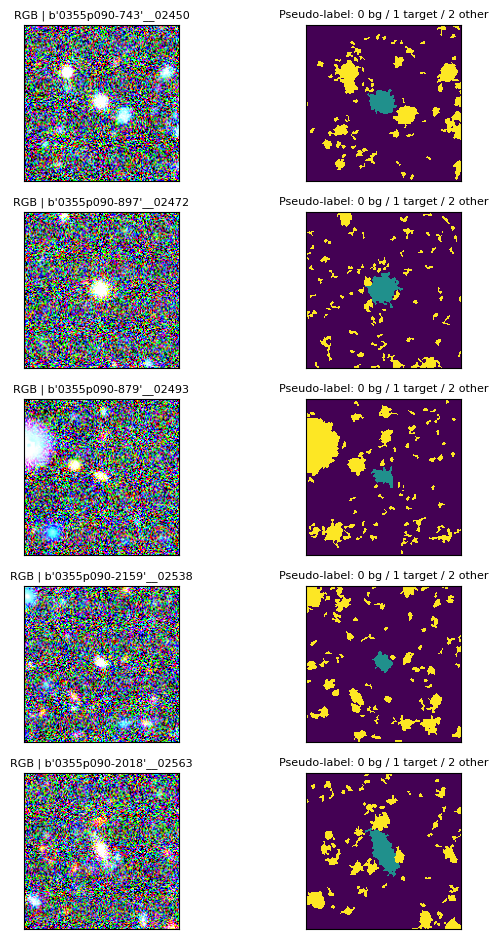

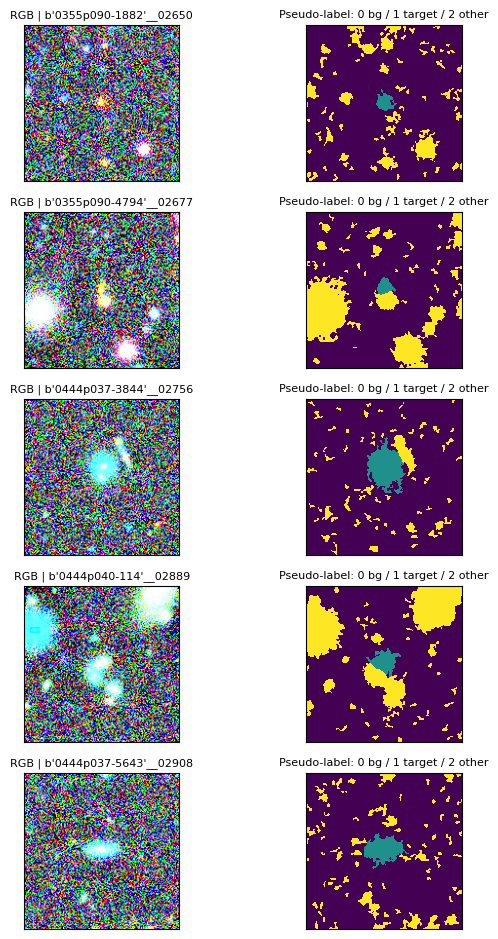

In [6]:
rng = np.random.default_rng(SEED)
review_indices = np.sort(rng.choice(len(ids), size=min(50, len(ids)), replace=False))
for page_start in range(0, len(review_indices), 5):
    page = review_indices[page_start:page_start+5]
    fig, axes = plt.subplots(len(page), 2, figsize=(7, 1.9*len(page)), squeeze=False)
    for row, i in enumerate(page):
        axes[row,0].imshow(rgb[i]); axes[row,0].set_title(f'RGB | {ids[i][:28]}', fontsize=8)
        axes[row,1].imshow(masks[i], vmin=0, vmax=2, cmap='viridis', interpolation='nearest')
        axes[row,1].set_title('Pseudo-label: 0 bg / 1 target / 2 other', fontsize=8)
        for ax in axes[row]: ax.set_xticks([]); ax.set_yticks([])
    fig.tight_layout()
    fig.savefig(PSEUDO_DIR / f'qc_gallery_{page_start//5+1:02d}.png', dpi=100)
    plt.show(); plt.close(fig)


In [7]:
# After visually reviewing all ten pages, list clearly broken IDs here.
# Keep the array empty only if all reviewed examples are acceptable.
MANUAL_DROP_IDS = []  # e.g. ['survey-object-id__00042']

qc = pd.read_csv(DATA_DIR / 'normalization_and_qc.csv')
invalid_indices = qc.index[qc['status'] != 'ok'].tolist()
auto_drop = set(ids[i] for i in invalid_indices)
all_drop = sorted(auto_drop.union(str(x) for x in MANUAL_DROP_IDS))
valid_indices = update_valid_indices(ROOT, all_drop)
print(f'Excluded {len(all_drop)} cutouts ({len(invalid_indices)} automatic empty/invalid labels, '
      f'{len(set(MANUAL_DROP_IDS))} manual). Valid images: {len(valid_indices)}')
run_status_path=ROOT/'results'/'metrics'/'run_status.json'
run_status_path.parent.mkdir(parents=True,exist_ok=True)
if len(valid_indices) < int(0.80 * N_IMAGES):
    run_status_path.write_text(json.dumps({'status':'invalid_pseudolabels','n_images':N_IMAGES,
        'n_valid_masks':int(len(valid_indices)),'reason':'Fewer than 80% of pseudo-labels passed QC.'},indent=2),encoding='utf-8')
    raise RuntimeError(f'Only {len(valid_indices)}/{N_IMAGES} pseudo-labels passed quality checks. '
                       'Stop here and inspect normalization_and_qc.csv before training.')
run_status_path.write_text(json.dumps({'status':'pseudo_labels_valid','n_images':N_IMAGES,
    'n_valid_masks':int(len(valid_indices)),'split_seed':SEED},indent=2),encoding='utf-8')


Excluded 0 cutouts (0 automatic empty/invalid labels, 0 manual). Valid images: 3000


102

## 3. Propose a challenging held-out test set

The code ranks test cutouts by the fraction of pixels labeled as other sources, which surfaces blends and source contamination. Review the candidates below and edit `USER_HARD_SET_IDS` to select about 20 by hand. If left empty, the saved set is explicitly marked as automatically proposed rather than hand-selected.


In [ ]:
valid = set(valid_indices.tolist())
test_idx = [i for i in split['test_indices'] if i in valid]
other_fraction = np.asarray([(masks[i] == 2).mean() for i in test_idx])
candidate_pos = np.argsort(other_fraction)[::-1][:min(30, len(test_idx))]
candidate_idx = [test_idx[p] for p in candidate_pos]
for page_start in range(0, len(candidate_idx), 6):
    page = candidate_idx[page_start:page_start+6]
    fig, axes = plt.subplots(len(page), 2, figsize=(7, 1.8*len(page)), squeeze=False)
    for row, i in enumerate(page):
        axes[row,0].imshow(rgb[i]); axes[row,0].set_title(f'{i}: {ids[i][:24]}', fontsize=7)
        axes[row,1].imshow(masks[i], vmin=0, vmax=2, cmap='viridis', interpolation='nearest')
        axes[row,1].set_title(f'other-source pixels {100*(masks[i]==2).mean():.1f}%', fontsize=7)
        for ax in axes[row]: ax.set_xticks([]); ax.set_yticks([])
    fig.tight_layout()
    fig.savefig(PSEUDO_DIR/f'hard_set_candidates_{page_start//6+1:02d}.png', dpi=100)
    plt.show(); plt.close(fig)

USER_HARD_SET_IDS = [
    "b'0436p025-4164'__00155",
    "b'0436p025-6365'__00366",
    "b'0438p017-4669'__01697",
    "b'0436p025-6046'__00277",
    "b'0444p040-114'__02889",
    "b'0436p025-4933'__00211",
    "b'0436p025-4188'__00275",
    "b'0453p027-1037'__01294",
    "b'0337p095-3620'__01042",
    "b'0436p025-1439'__00227",
    "b'0455p047-3091'__00893",
    "b'0453p027-5669'__01550",
    "b'0438p017-4152'__01746",
    "b'0355p090-4794'__02677",
    "b'0345p092-4322'__02274",
    "b'0436p025-6053'__00286",
    "b'0355p090-758'__02706",
    "b'0337p095-3929'__01013",
    "b'0453p027-5797'__01564",
    "b'0436p025-4192'__00145",
]  # Visually reviewed hard test set.
if USER_HARD_SET_IDS:
    hard_ids = [str(x) for x in USER_HARD_SET_IDS]
    allowed = {str(ids[i]) for i in test_idx}
    if any(x not in allowed for x in hard_ids): raise ValueError('Hard-set IDs must belong to the test split.')
    selection = 'manually selected after visual review of the 20 hard-set candidates'
else:
    hard_ids = [str(ids[i]) for i in candidate_idx[:20]]
    selection = 'automatic high-other-source candidates; hand review still recommended'
(PSEUDO_DIR/'hard_set_ids.json').write_text(json.dumps({'selection':selection,'ids':hard_ids},indent=2),encoding='utf-8')
print('Saved hard-set proposal:', selection, '| n=',len(hard_ids))


## Outputs and checks

The pseudo-label masks and image arrays are aligned row by row with `image_ids.npy`; the split JSON stores indices into that stable ordering. Empty masks and failed detections are flagged in the QC CSV and excluded from training unless manually retained. Keep the IDs, masks, split, and saved normalization statistics together.
